In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA

# Load the dataset
wine = load_wine(as_frame=True)

df = wine.frame

In [2]:
# Separate features and target
X = df.drop(columns = "target")
y = df["target"]

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [3]:
# Standardize: each feature gets mean 0 and standard deviation 1
mlp_pipeline = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(5,4), max_iter=500, random_state=42)
)

mlp_pipeline.fit(x_train,y_train)

acc = mlp_pipeline.score(x_test, y_test)
print(acc)

1.0


## 3. Experiment with network architecture

  architecture  parameters  train_accuracy  test_accuracy
0         (5,)          88             1.0       0.972222
1        (10,)         173             1.0       0.972222
2        (20,)         343             1.0       1.000000
3        (50,)         853             1.0       1.000000
4     (20, 10)         523             1.0       1.000000
5     (50, 20)        1783             1.0       1.000000


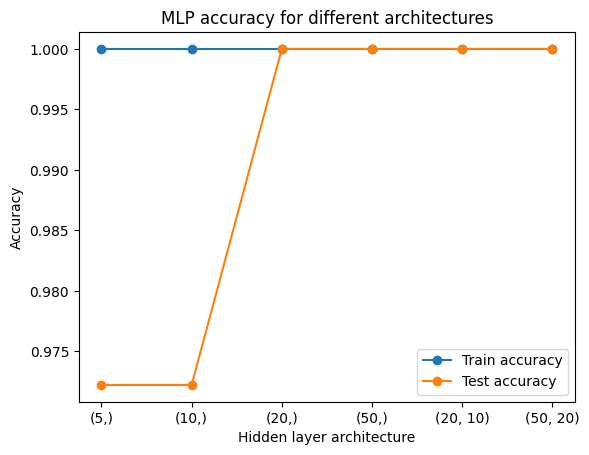

In [4]:
architectures = [(5,), (10,), (20,), (50,), (20, 10), (50, 20)]
results = []

for arch in architectures:
    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes = arch, max_iter = 1000, random_state = 42)
    )
    model.fit(x_train, y_train)
    n_params = sum(w.size for w in model[-1].coefs_) + sum(b.size for b in model[-1].intercepts_)
    results.append({
        "architecture": str(arch),
        "parameters": n_params,
        "train_accuracy": accuracy_score(y_train, model.predict(x_train)),
        "test_accuracy": accuracy_score(y_test, model.predict(x_test)),
    })

arch_df = pd.DataFrame(results)
print(arch_df)

# Plot
labels = [str(a) for a in architectures]
plt.plot(labels, arch_df["train_accuracy"], marker="o", label="Train accuracy")
plt.plot(labels, arch_df["test_accuracy"], marker="o", label="Test accuracy")
plt.xlabel("Hidden layer architecture")
plt.ylabel("Accuracy")
plt.title("MLP accuracy for different architectures")
plt.legend()
plt.show()

Questions:
1. 

## 4. Compare the neural network with previous models

In [5]:
from sklearn.ensemble import RandomForestClassifier

# Neural Network
mlp_pipeline.fit(x_train, y_train)
mlp_pred = mlp_pipeline.predict(x_test)
mlp_acc = accuracy_score(y_test, mlp_pred)

# Logistic Regression
log_model = make_pipeline(
   StandardScaler(),
   LogisticRegression(max_iter=1000, random_state=42)
)

log_model.fit(x_train, y_train)
log_pred = log_model.predict(x_test)
log_acc = accuracy_score(y_test, log_pred)

# Decision Tree
tree_model = DecisionTreeClassifier(
   max_depth=3,
   random_state=42
)

tree_model.fit(x_train, y_train)
tree_pred = tree_model.predict(x_test)
tree_acc = accuracy_score(y_test, tree_pred)

# Random Forest
rf_model = RandomForestClassifier(
   random_state=42
)

rf_model.fit(x_train, y_train)
rf_pred = rf_model.predict(x_test)
rf_acc = accuracy_score(y_test, rf_pred)

# Comparison table
results = pd.DataFrame({
   "Model": [
       "Logistic Regression",
       "Decision Tree",
       "Random Forest",
       "Neural Network"
   ],
   "Test Accuracy": [
       log_acc,
       tree_acc,
       rf_acc,
       mlp_acc
   ]
})

print(results)


                 Model  Test Accuracy
0  Logistic Regression       1.000000
1        Decision Tree       0.944444
2        Random Forest       1.000000
3       Neural Network       1.000000


1. Which models performed similarly?
Logistic Regression, Random Forest, and the Neural Network performed similarly, as all three achieved a test accuracy of 100%. This means that all three models correctly classified every wine sample in the test set.

2. Which models performed differently?
The Decision Tree performed slightly differently from the other models. It achieved a test accuracy of 94.44%, while the other methods achieved 100%. Therefore, the Decision Tree made some incorrect predictions on the test set, although its overall performance was still high.

3. Does the neural network clearly outperform the simpler models?
No, Neural Network does not outperform the simpler models. Although it achieved 100% test accuracy, Logistic Regression and Rando Forest also achieved 100%. This shows that a more complex model such as Neural Network is not necessarily needed for this dataset, since a simpler model can achieve hte same performance.

4. Is accuracy alone enough to decide which model is best?
No, other factoes should also be considered such as show well each model performs for individual classes, possibility of overfitting, model complexity, training time, etc. 

5. What are some of the advantages of neural networks?
Neural networks cna learn complex nad nonlinear relationships between features. They are also flexible and can model patterns that maybe difficult for simpler model to capture. The model can also be adjusted by changing the number of neurons and hidden layers for more complicated problems.

6. What are some of the disadvantages of neural networks compared with simpler models?
Neural networks are more complex and less interpretable than simpler models such as Logistic Regression or Decision Trees. They may also require more computation, careful feature scaling, and tuning of parameters such as the number of hidden layers and neurons. More complex networks can also have a greater risk of overfitting, especially when the dataset is small.
